<a href="https://colab.research.google.com/github/achyutcbhat/Enterprise-Network-Cyber-Attack-Intrusion-Detection-IDS-/blob/main/Problem_56_Enterprise_IDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 56: Enterprise Network Cyber Attack & Intrusion Detection (IDS)

**Application Domain:** Cybersecurity & Network Infrastructure Defense

**Dataset:** NSL-KDD Network Intrusion Dataset

**Machine Learning Algorithms:**
- Decision Tree Classifier (Gini and Entropy)
- Gaussian Naive Bayes
- Linear Support Vector Machine (SVM)

**Objective:** Classify network traffic into five categories: Normal, DoS, Probe, R2L, and U2R, and compare the models' performance.

# STEP 1

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nStep 1 verification successful!")



Pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Scikit-learn: 1.6.1

Step 1 verification successful!


# STEP 2

In [ ]:

!git clone https://github.com/jmnwong/NSL-KDD-Dataset.git


fatal: destination path 'NSL-KDD-Dataset' already exists and is not an empty directory.


In [ ]:

import os

repo_path = "/content/NSL-KDD-Dataset"

for file in sorted(os.listdir(repo_path)):
    if file.endswith((".txt", ".arff")):
        print(file)


KDDTest+.arff
KDDTest+.txt
KDDTest-21.arff
KDDTest-21.txt
KDDTrain+.arff
KDDTrain+.txt
KDDTrain+_20Percent.arff
KDDTrain+_20Percent.txt


In [ ]:

import pandas as pd
import os

columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count",
    "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_path = os.path.join(repo_path, "KDDTrain+.txt")
test_path = os.path.join(repo_path, "KDDTest+.txt")

train_df = pd.read_csv(train_path, names=columns)
test_df = pd.read_csv(test_path, names=columns)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)
print("Total columns:", len(columns))

print("\nFirst 5 training records:")
display(train_df.head())

print("\nTraining data types:")
print(train_df.dtypes)

print("\nTraining attack labels:")
print(train_df["label"].value_counts())

print("\nTesting attack labels:")
print(test_df["label"].value_counts())


Training dataset shape: (125973, 43)
Testing dataset shape: (22544, 43)
Total columns: 43

First 5 training records:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21



Training data types:
duration                         int64
protocol_type                   object
service                         object
flag                            object
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv

# STEP 3

In [ ]:

# Check missing values
print("Missing values in training data:", train_df.isnull().sum().sum())
print("Missing values in testing data:", test_df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate training rows:", train_df.duplicated().sum())
print("Duplicate testing rows:", test_df.duplicated().sum())


Missing values in training data: 0
Missing values in testing data: 0
Duplicate training rows: 0
Duplicate testing rows: 0


In [ ]:

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining data types:")
print(train_df.dtypes.value_counts())

print("\nCategorical columns:")
print(train_df.select_dtypes(include=["object"]).columns.tolist())

print("\nNumerical columns:")
print(train_df.select_dtypes(exclude=["object"]).columns.tolist())


Training shape: (125973, 43)
Testing shape: (22544, 43)

Training data types:
int64      24
float64    15
object      4
Name: count, dtype: int64

Categorical columns:
['protocol_type', 'service', 'flag', 'label']

Numerical columns:
['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'difficulty']


In [ ]:

print("Number of unique training attack labels:",
      train_df["label"].nunique())

print("\nTraining attack label counts:")
print(train_df["label"].value_counts())

print("\nNumber of unique testing attack labels:",
      test_df["label"].nunique())

print("\nTesting attack label counts:")
print(test_df["label"].value_counts())

print("\nAttack labels found only in testing data:")
print(sorted(set(test_df["label"]) - set(train_df["label"])))


Number of unique training attack labels: 23

Training attack label counts:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

Number of unique testing attack labels: 38

Testing attack label counts:
label
normal             9711
neptune            4657
guess_passwd       1231
mscan               996
warezmaster         944
apache2             737
satan               735
processtable        685
smurf               665
back                35

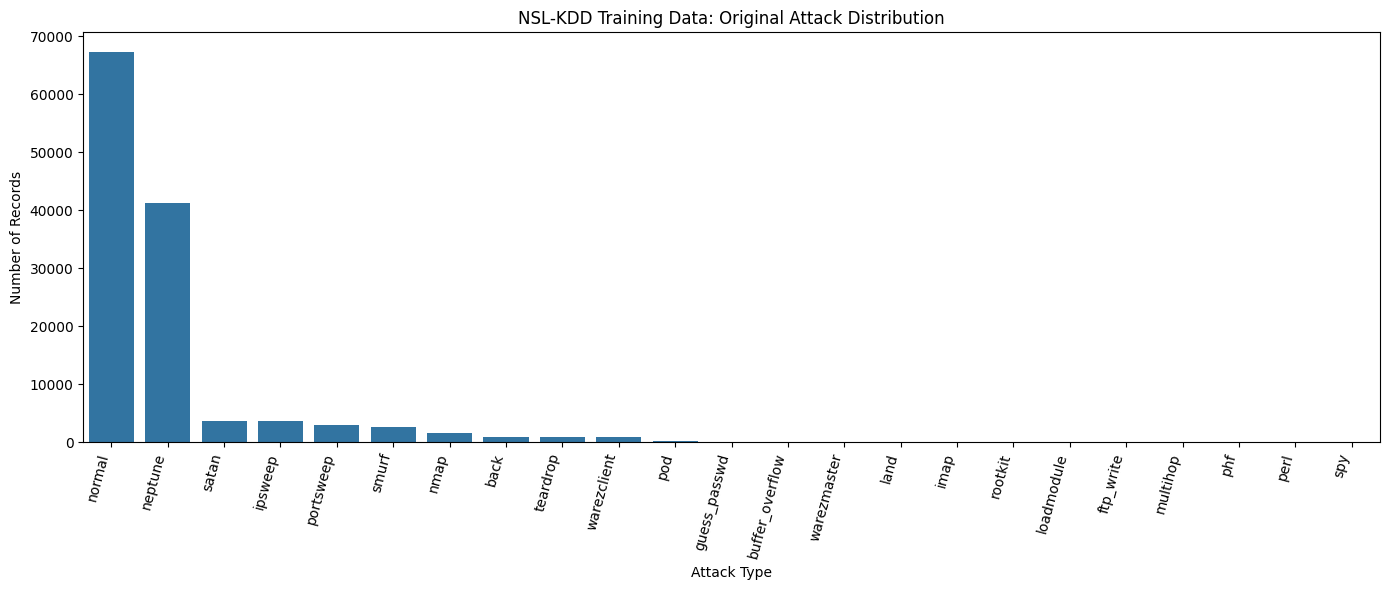

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

attack_counts = train_df["label"].value_counts()

plt.figure(figsize=(14, 6))
sns.barplot(x=attack_counts.index, y=attack_counts.values)

plt.title("NSL-KDD Training Data: Original Attack Distribution")
plt.xlabel("Attack Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


# STEP 4

In [ ]:
# Individual attack types grouped into five categories

dos_attacks = [
    "back", "land", "neptune", "pod", "smurf", "teardrop",
    "mailbomb", "apache2", "processtable", "udpstorm"
]

probe_attacks = [
    "satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"
]

r2l_attacks = [
    "guess_passwd", "ftp_write", "imap", "phf", "multihop",
    "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
    "snmpguess", "snmpgetattack", "httptunnel", "sendmail",
    "named", "worm"
]

u2r_attacks = [
    "buffer_overflow", "loadmodule", "perl", "rootkit",
    "ps", "sqlattack", "xterm"
]


def map_attack(label):
    if label == "normal":
        return "Normal"
    elif label in dos_attacks:
        return "DoS"
    elif label in probe_attacks:
        return "Probe"
    elif label in r2l_attacks:
        return "R2L"
    elif label in u2r_attacks:
        return "U2R"
    else:
        return "Unknown"


# Create the category column in both datasets
train_df["attack_category"] = train_df["label"].apply(map_attack)
test_df["attack_category"] = test_df["label"].apply(map_attack)

print("Training categories created.")
print("Testing categories created.")

Training categories created.
Testing categories created.


In [ ]:
print("Training category counts:")
print(train_df["attack_category"].value_counts())

print("\nTesting category counts:")
print(test_df["attack_category"].value_counts())

print("\nUnknown labels in training data:")
print(sorted(train_df.loc[
    train_df["attack_category"] == "Unknown", "label"
].unique()))

print("\nUnknown labels in testing data:")
print(sorted(test_df.loc[
    test_df["attack_category"] == "Unknown", "label"
].unique()))

Training category counts:
attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Testing category counts:
attack_category
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64

Unknown labels in training data:
[]

Unknown labels in testing data:
[]


# STEP 5

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate target labels from input features
target_column = "attack_category"

drop_columns = ["label", "difficulty", "attack_category"]

X_train_raw = train_df.drop(columns=drop_columns)
X_test_raw = test_df.drop(columns=drop_columns)

y_train = train_df[target_column]
y_test = test_df[target_column]

# Identify categorical and numerical columns
categorical_features = X_train_raw.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train_raw.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

# Fit ONLY on training data; transform both datasets
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("\nPreprocessing completed.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target classes:")
print(sorted(y_train.unique()))

print("\nTesting target classes:")
print(sorted(y_test.unique()))

Categorical features: ['protocol_type', 'service', 'flag']
Number of numerical features: 38
Number of categorical features: 3

Preprocessing completed.
X_train shape: (125973, 122)
X_test shape: (22544, 122)
y_train shape: (125973,)
y_test shape: (22544,)

Training target classes:
['DoS', 'Normal', 'Probe', 'R2L', 'U2R']

Testing target classes:
['DoS', 'Normal', 'Probe', 'R2L', 'U2R']


In [ ]:
import numpy as np

print("Training features contain NaN:", np.isnan(X_train).any())
print("Testing features contain NaN:", np.isnan(X_test).any())

print("Training features contain infinity:", np.isinf(X_train).any())
print("Testing features contain infinity:", np.isinf(X_test).any())

print("Training and testing feature counts match:",
      X_train.shape[1] == X_test.shape[1])

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training features contain NaN: False
Testing features contain NaN: False
Training features contain infinity: False
Testing features contain infinity: False
Training and testing feature counts match: True
Training records: 125973
Testing records: 22544


## STEP 6

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
import time

# Define the four model configurations
models = {
    "Decision Tree (Gini)": DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),

    "Decision Tree (Entropy)": DecisionTreeClassifier(
        criterion="entropy",
        random_state=42
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Linear SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=10000,
        dual="auto"
    )
}

# Train each model and record training time
training_times = {}

for name, model in models.items():
    print(f"Training {name}...")

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed_time = time.perf_counter() - start_time

    training_times[name] = elapsed_time

    print(f"Completed in {elapsed_time:.2f} seconds\n")

print("All model training completed.")

Training Decision Tree (Gini)...
Completed in 5.81 seconds

Training Decision Tree (Entropy)...
Completed in 1.53 seconds

Training Gaussian Naive Bayes...
Completed in 0.43 seconds

Training Linear SVM...
Completed in 82.18 seconds

All model training completed.


In [ ]:
print("Model training summary")
print("-" * 45)

for name, model in models.items():
    print(f"{name}:")
    print(f"  Trained: {hasattr(model, 'classes_')}")
    print(f"  Training time: {training_times[name]:.2f} seconds")

    if name.startswith("Decision Tree"):
        print(f"  Tree depth: {model.get_depth()}")
        print(f"  Number of leaves: {model.get_n_leaves()}")

    print()

Model training summary
---------------------------------------------
Decision Tree (Gini):
  Trained: True
  Training time: 5.81 seconds
  Tree depth: 28
  Number of leaves: 317

Decision Tree (Entropy):
  Trained: True
  Training time: 1.53 seconds
  Tree depth: 17
  Number of leaves: 304

Gaussian Naive Bayes:
  Trained: True
  Training time: 0.43 seconds

Linear SVM:
  Trained: True
  Training time: 82.18 seconds



# STEP 7

In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

evaluation_results = []
classification_reports = {}

for name, model in models.items():
    # Predict on the held-out test dataset
    y_pred = model.predict(X_test)

    # Calculate overall metrics
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

    # Save category-level metrics
    classification_reports[name] = classification_report(
        y_test,
        y_pred,
        labels=["Normal", "DoS", "Probe", "R2L", "U2R"],
        output_dict=True,
        zero_division=0
    )

# Display the model comparison table
evaluation_df = pd.DataFrame(evaluation_results)

print("MODEL PERFORMANCE COMPARISON")
display(
    evaluation_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Decision Tree (Gini),0.7641,0.8640,0.5421,0.5724,0.7249
1,Decision Tree (Entropy),0.7760,0.7572,0.5511,0.5581,0.7391
2,Gaussian Naive Bayes,0.4730,0.5063,0.4324,0.3300,0.4925
3,Linear SVM,0.7432,0.7370,0.5336,0.5550,0.7014


In [ ]:
rare_attack_results = []

for name, report in classification_reports.items():
    for category in ["R2L", "U2R"]:
        rare_attack_results.append({
            "Model": name,
            "Category": category,
            "Precision": report[category]["precision"],
            "Recall": report[category]["recall"],
            "F1-score": report[category]["f1-score"],
            "Support": report[category]["support"]
        })

rare_attack_df = pd.DataFrame(rare_attack_results)

print("RARE ATTACK CATEGORY PERFORMANCE")
display(
    rare_attack_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

RARE ATTACK CATEGORY PERFORMANCE


,Model,Category,Precision,Recall,F1-score,Support
0,Decision Tree (Gini),R2L,0.9572,0.0620,0.1165,2887.000000
1,Decision Tree (Gini),U2R,0.9375,0.2239,0.3614,67.000000
2,Decision Tree (Entropy),R2L,0.9526,0.0835,0.1535,2887.000000
3,Decision Tree (Entropy),U2R,0.3889,0.1045,0.1647,67.000000
4,Gaussian Naive Bayes,R2L,0.1595,0.3242,0.2138,2887.000000
5,Gaussian Naive Bayes,U2R,0.0423,0.6567,0.0794,67.000000
6,Linear SVM,R2L,0.4891,0.0312,0.0586,2887.000000
7,Linear SVM,U2R,0.8421,0.2388,0.3721,67.000000


In [ ]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=["Normal", "DoS", "Probe", "R2L", "U2R"],
        zero_division=0
    ))


Decision Tree (Gini)
              precision    recall  f1-score   support

      Normal       0.67      0.96      0.79      9711
         DoS       0.96      0.82      0.89      7458
       Probe       0.80      0.64      0.71      2421
         R2L       0.96      0.06      0.12      2887
         U2R       0.94      0.22      0.36        67

    accuracy                           0.76     22544
   macro avg       0.86      0.54      0.57     22544
weighted avg       0.82      0.76      0.72     22544


Decision Tree (Entropy)
              precision    recall  f1-score   support

      Normal       0.69      0.97      0.81      9711
         DoS       0.96      0.78      0.86      7458
       Probe       0.79      0.81      0.80      2421
         R2L       0.95      0.08      0.15      2887
         U2R       0.39      0.10      0.16        67

    accuracy                           0.78     22544
   macro avg       0.76      0.55      0.56     22544
weighted avg       0.82      0

## STEP 8

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score
import pandas as pd

# Split the original training data before fitting preprocessing
X_subtrain_raw, X_val_raw, y_subtrain, y_val = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Fit preprocessing only on the subtraining data
depth_preprocessor = clone(preprocessor)
X_subtrain = depth_preprocessor.fit_transform(X_subtrain_raw)
X_val = depth_preprocessor.transform(X_val_raw)

depth_results = []

depths_to_test = list(range(2, 31, 2)) + [None]

for criterion in ["gini", "entropy"]:
    for depth in depths_to_test:
        tree = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        tree.fit(X_subtrain, y_subtrain)
        val_pred = tree.predict(X_val)

        depth_results.append({
            "Criterion": criterion,
            "Max Depth": "Unlimited" if depth is None else depth,
            "Actual Depth": tree.get_depth(),
            "Accuracy": accuracy_score(y_val, val_pred),
            "DoS Recall": recall_score(
                y_val, val_pred,
                labels=["DoS"],
                average="macro",
                zero_division=0
            ),
            "Macro F1": __import__("sklearn.metrics").metrics.f1_score(
                y_val, val_pred,
                average="macro",
                zero_division=0
            )
        })

depth_df = pd.DataFrame(depth_results)

display(
    depth_df.style.format({
        "Accuracy": "{:.4f}",
        "DoS Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

,Criterion,Max Depth,Actual Depth,Accuracy,DoS Recall,Macro F1
0,gini,2,2,0.9076,0.9729,0.5005
1,gini,4,4,0.9779,0.9919,0.6538
2,gini,6,6,0.9894,0.9966,0.8061
3,gini,8,8,0.9952,0.9995,0.9056
4,gini,10,10,0.9965,0.9992,0.9384
5,gini,12,12,0.9977,0.9992,0.9546
6,gini,14,14,0.9977,0.9992,0.9450
7,gini,16,16,0.9976,0.9992,0.9368
8,gini,18,18,0.9977,0.9993,0.9297
9,gini,20,20,0.9977,0.9993,0.9365


In [ ]:
target_recall = 0.99

qualified_trees = depth_df[
    depth_df["DoS Recall"] >= target_recall
].sort_values(
    by=["Macro F1", "Accuracy"],
    ascending=False
)

if qualified_trees.empty:
    print("No tested tree configuration achieved 99% DoS recall.")
    best_dos_tree = depth_df.sort_values(
        by="DoS Recall",
        ascending=False
    ).head(1)

    print("\nBest configuration for DoS recall:")
    display(best_dos_tree)
else:
    print("Configurations achieving at least 99% DoS recall:")
    display(qualified_trees)

Configurations achieving at least 99% DoS recall:


,Criterion,Max Depth,Actual Depth,Accuracy,DoS Recall,Macro F1
5,gini,12,12,0.997698,0.999238,0.954585
12,gini,26,26,0.998293,0.999673,0.951080
6,gini,14,14,0.997658,0.999238,0.945046
11,gini,24,24,0.998135,0.999565,0.943984
10,gini,22,22,0.998135,0.999673,0.938442
4,gini,10,10,0.996507,0.999238,0.938405
13,gini,28,28,0.998095,0.999673,0.937448
14,gini,30,28,0.998095,0.999673,0.937448
15,gini,Unlimited,28,0.998095,0.999673,0.937448
7,gini,16,16,0.997619,0.999238,0.936816


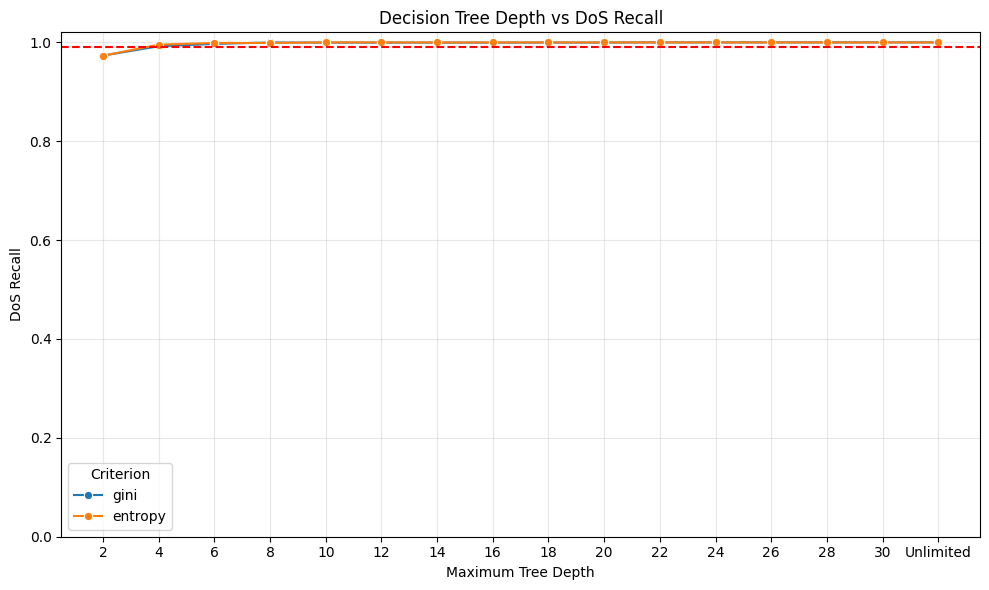

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = depth_df.copy()
plot_df["Depth Label"] = plot_df["Max Depth"].astype(str)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=plot_df,
    x="Depth Label",
    y="DoS Recall",
    hue="Criterion",
    marker="o"
)

plt.axhline(
    y=0.99,
    linestyle="--",
    color="red",
    label="99% target"
)

plt.title("Decision Tree Depth vs DoS Recall")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("DoS Recall")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 9

In [ ]:
import time
import numpy as np
import pandas as pd

# Use exactly 10,000 test records for every model
N_BENCHMARK = 10_000

if X_test.shape[0] < N_BENCHMARK:
    raise ValueError("The test dataset contains fewer than 10,000 records.")

X_benchmark = X_test[:N_BENCHMARK]

REPEATS = 5
benchmark_results = []

for name, model in models.items():

    # Warm-up: exclude this prediction from the measurements
    model.predict(X_benchmark[:100])

    times = []

    # Repeat prediction timing using identical records
    for _ in range(REPEATS):
        start = time.perf_counter()
        predictions = model.predict(X_benchmark)
        elapsed = time.perf_counter() - start
        times.append(elapsed)

    median_time = float(np.median(times))

    benchmark_results.append({
        "Model": name,
        "Records": N_BENCHMARK,
        "Median Prediction Time (s)": median_time,
        "Time per Record (ms)": median_time / N_BENCHMARK * 1000,
        "Throughput (records/s)": N_BENCHMARK / median_time
    })

benchmark_df = pd.DataFrame(benchmark_results).sort_values(
    "Median Prediction Time (s)"
).reset_index(drop=True)

print("INFERENCE SPEED BENCHMARK")
print("Records per model:", N_BENCHMARK)
print("Timing repetitions:", REPEATS)
print("Reported time: median of repetitions\n")

display(
    benchmark_df.style.format({
        "Median Prediction Time (s)": "{:.6f}",
        "Time per Record (ms)": "{:.6f}",
        "Throughput (records/s)": "{:,.0f}"
    })
)

INFERENCE SPEED BENCHMARK
Records per model: 10000
Timing repetitions: 5
Reported time: median of repetitions



,Model,Records,Median Prediction Time (s),Time per Record (ms),Throughput (records/s)
0,Decision Tree (Entropy),10000,0.003591,0.000359,"2,784,765"
1,Decision Tree (Gini),10000,0.004117,0.000412,"2,429,195"
2,Linear SVM,10000,0.006572,0.000657,"1,521,709"
3,Gaussian Naive Bayes,10000,0.041011,0.004101,"243,835"


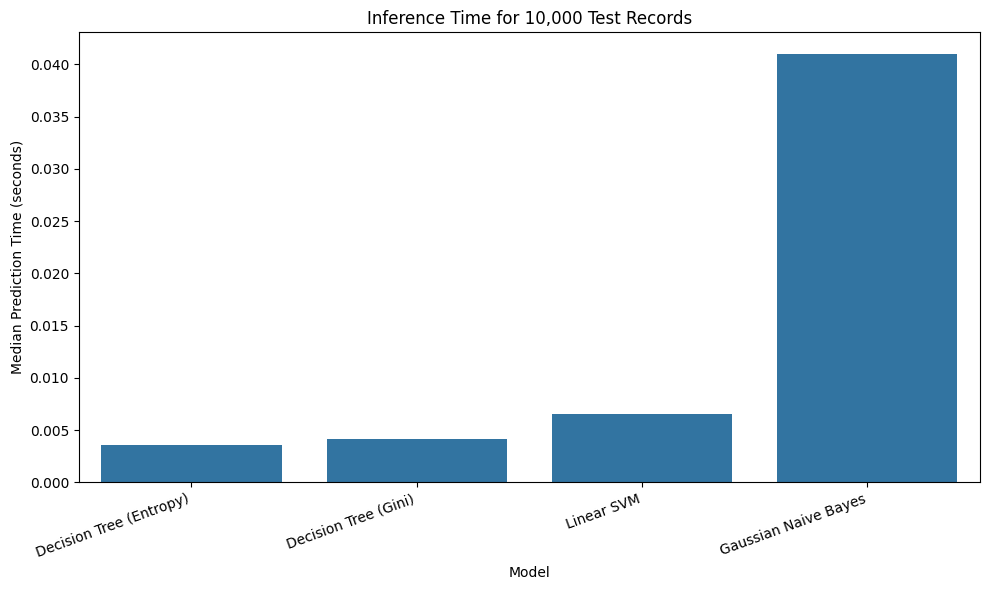

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=benchmark_df,
    x="Model",
    y="Median Prediction Time (s)"
)

plt.title("Inference Time for 10,000 Test Records")
plt.xlabel("Model")
plt.ylabel("Median Prediction Time (seconds)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# STEP 10

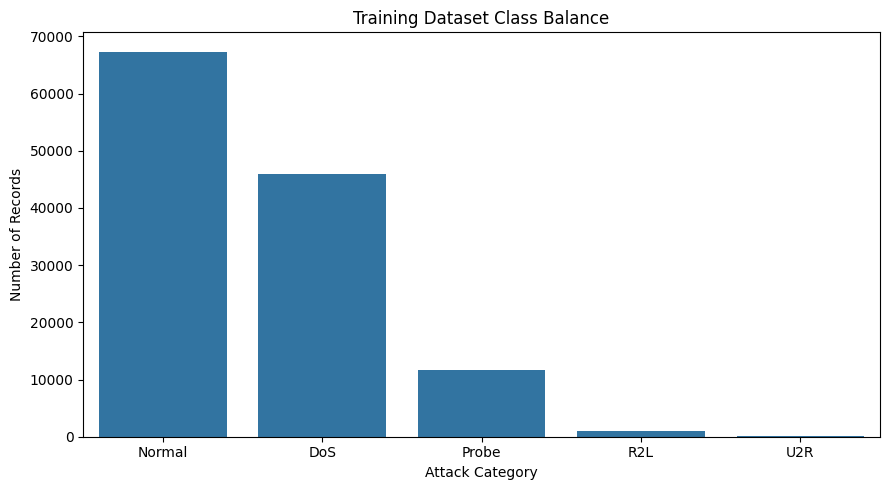

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

class_order = ["Normal", "DoS", "Probe", "R2L", "U2R"]
class_counts = train_df["attack_category"].value_counts().reindex(
    class_order, fill_value=0
)

plt.figure(figsize=(9, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Training Dataset Class Balance")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

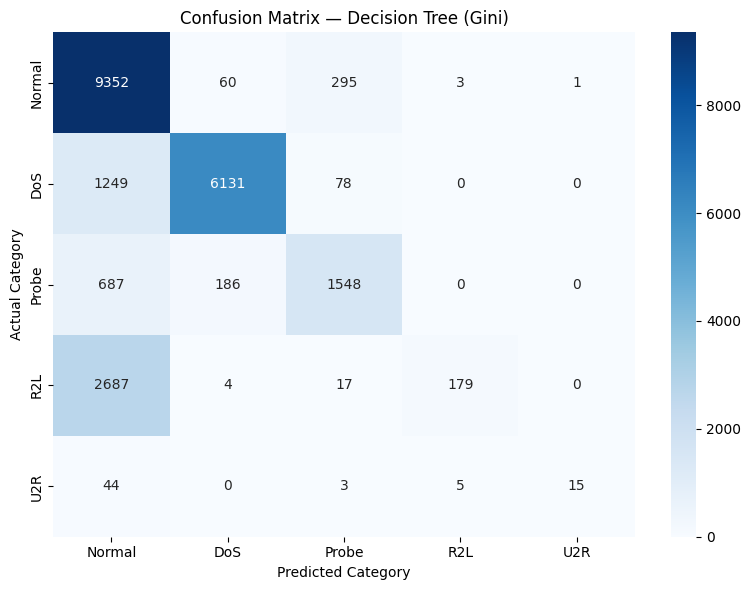

Confusion matrix shape: (5, 5)


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier

gini_model = models["Decision Tree (Gini)"]
y_pred_gini = gini_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_gini,
    labels=class_order
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order
)
plt.title("Confusion Matrix — Decision Tree (Gini)")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

print("Confusion matrix shape:", cm.shape)

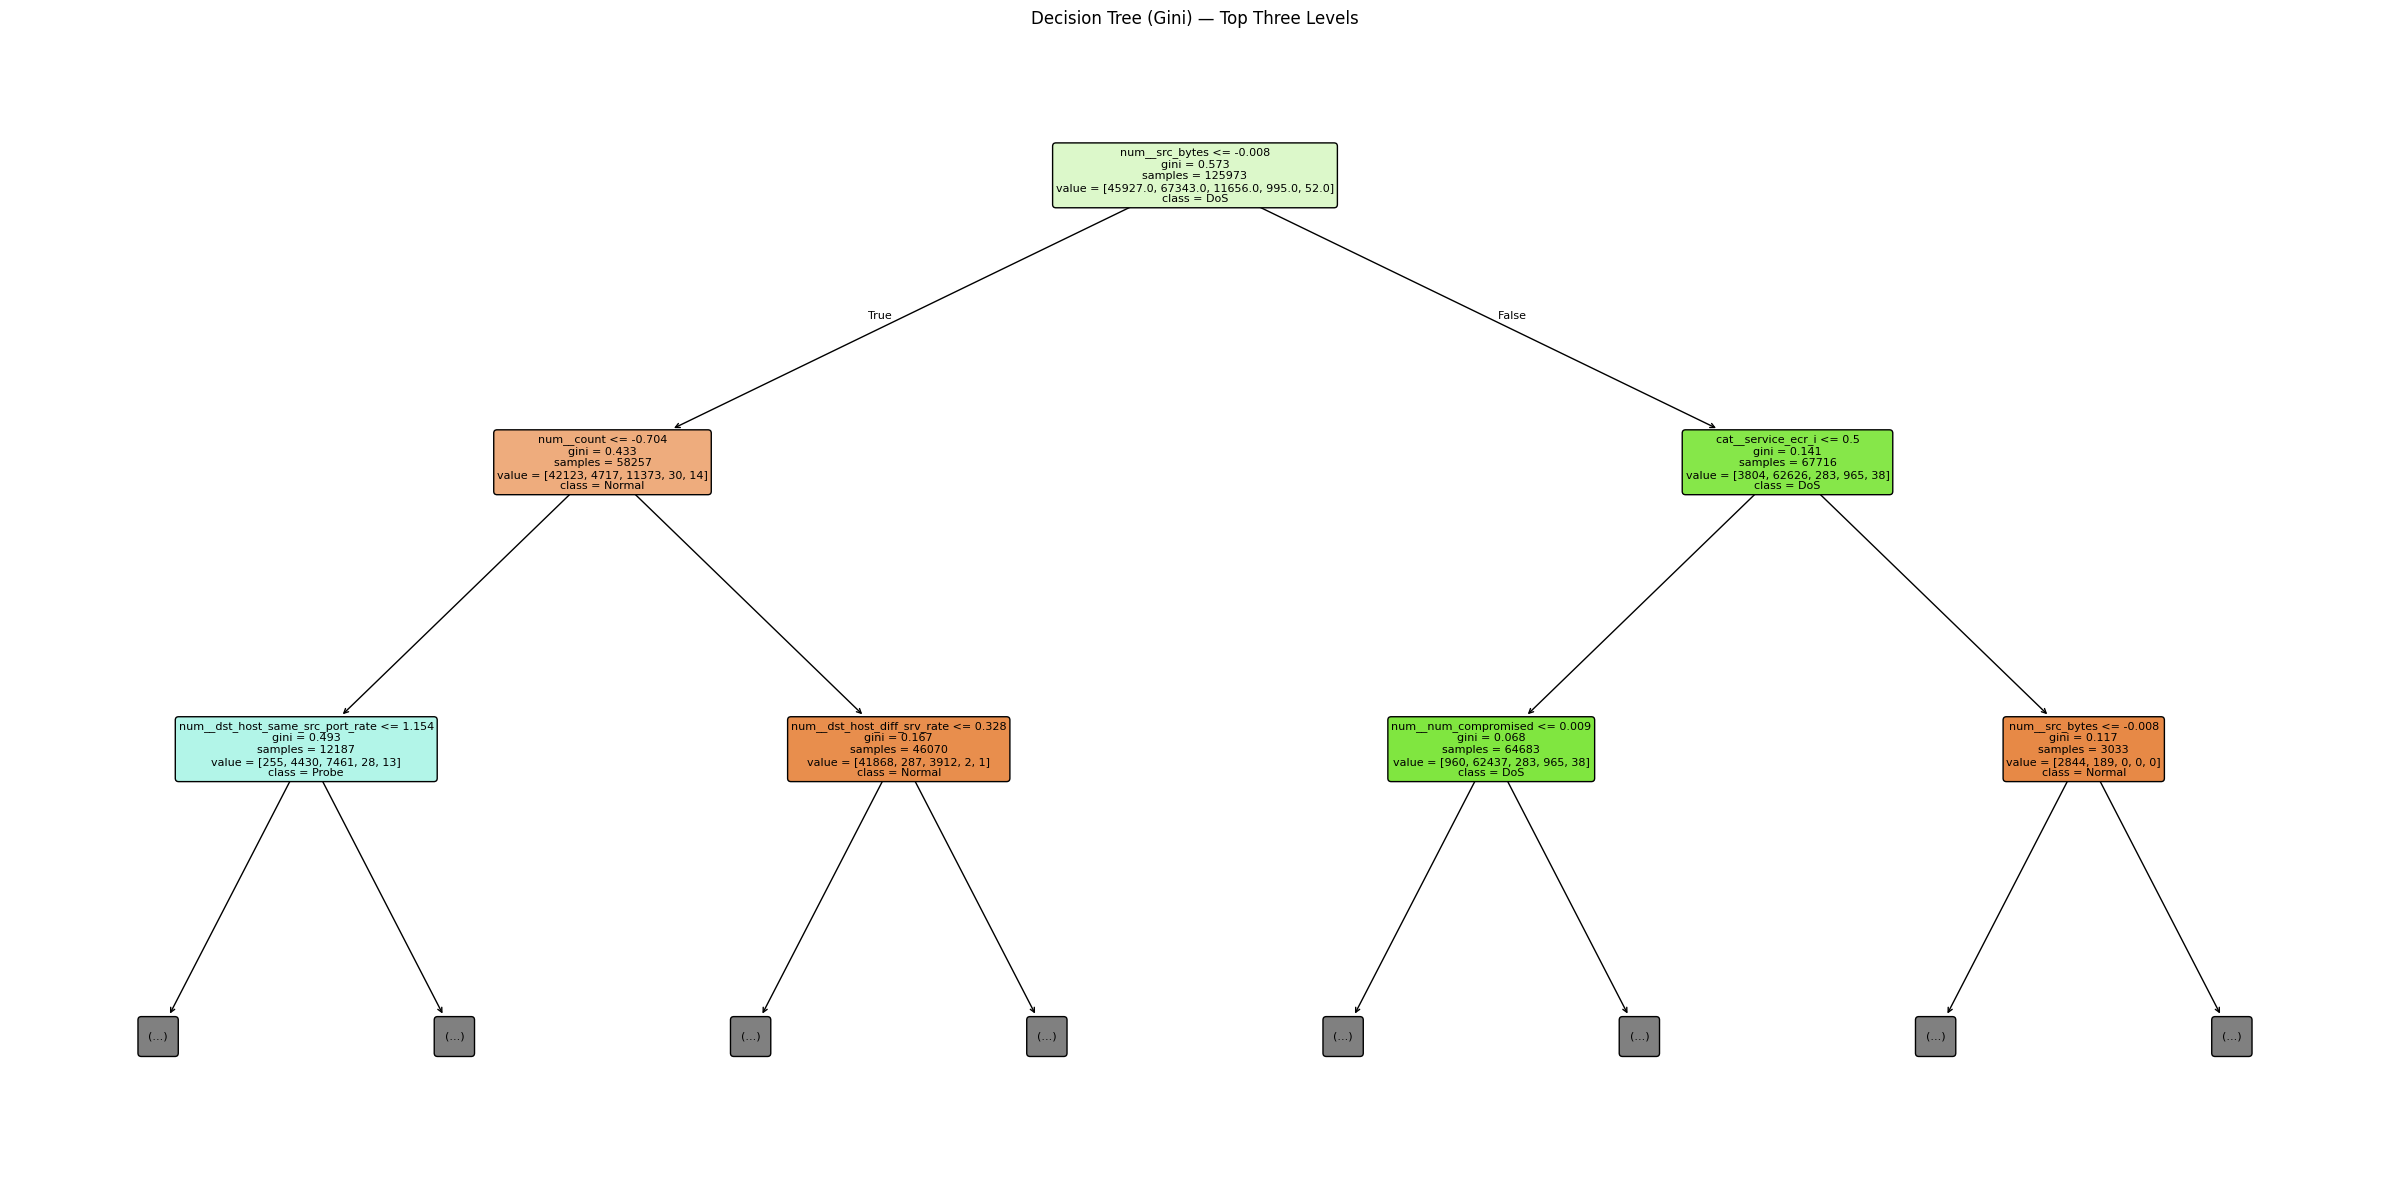

In [ ]:
from sklearn.tree import plot_tree

feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    gini_model,
    max_depth=2,
    feature_names=feature_names,
    class_names=class_order,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree (Gini) — Top Three Levels")
plt.tight_layout()
plt.show()

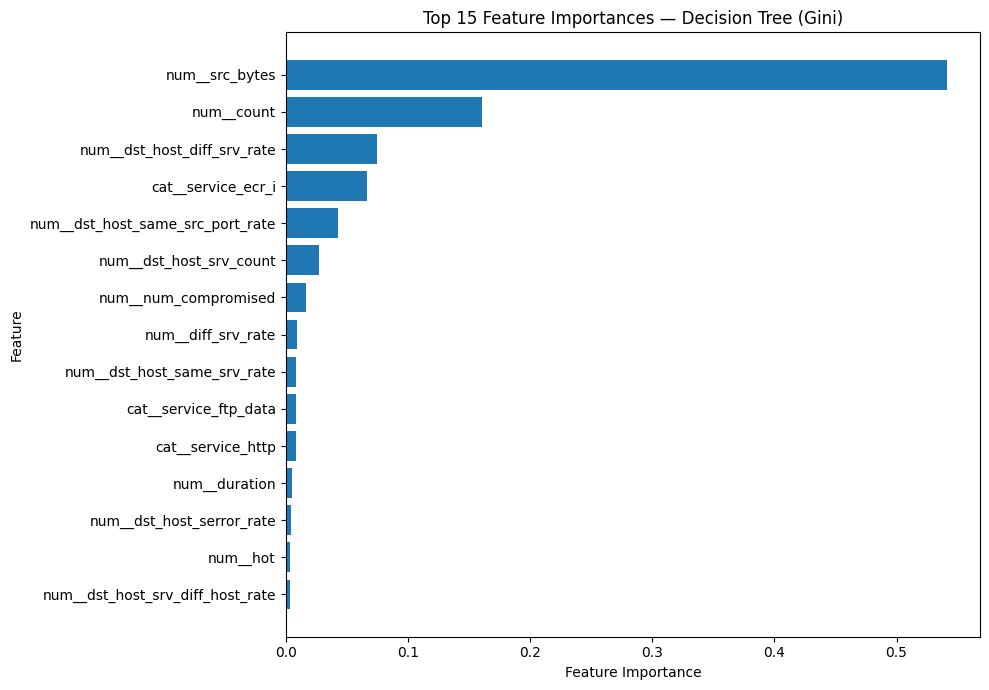

Top 5 features:


,Feature,Importance
0,num__src_bytes,0.541250
1,num__count,0.160335
2,num__dst_host_diff_srv_rate,0.074711
3,cat__service_ecr_i,0.066960
4,num__dst_host_same_src_port_rate,0.043014


In [ ]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gini_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
).head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.title("Top 15 Feature Importances — Decision Tree (Gini)")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 5 features:")
display(
    importance_df.sort_values(
        "Importance", ascending=False
    ).head(5).reset_index(drop=True)
)

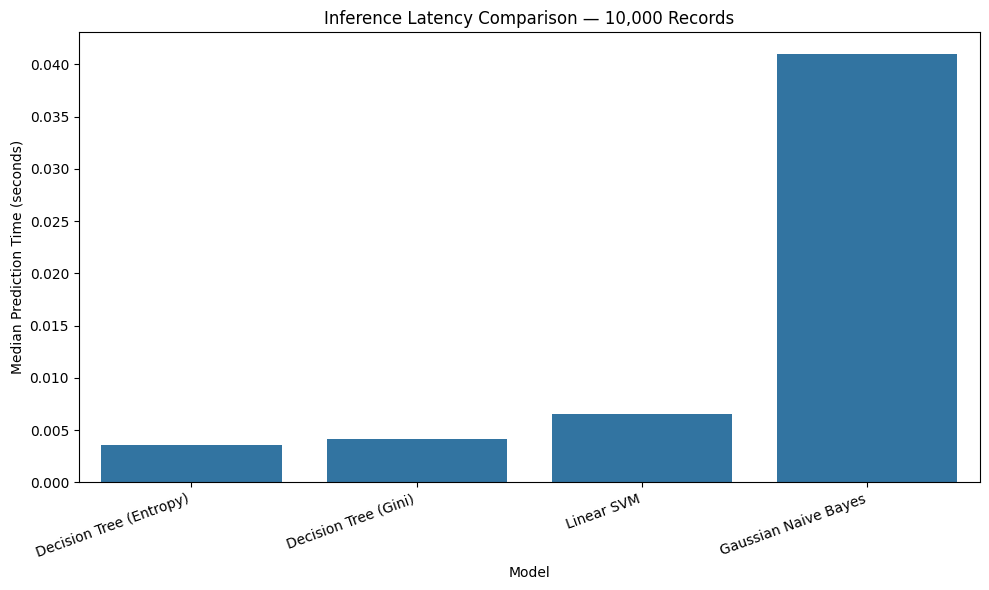

In [ ]:
plt.figure(figsize=(10, 6))

latency_plot = benchmark_df.sort_values(
    "Median Prediction Time (s)", ascending=True
)

sns.barplot(
    data=latency_plot,
    x="Model",
    y="Median Prediction Time (s)"
)

plt.title("Inference Latency Comparison — 10,000 Records")
plt.xlabel("Model")
plt.ylabel("Median Prediction Time (seconds)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print("GRAPH CHECKLIST")
print("1. Class balance bar chart: generated")
print("2. 5x5 confusion matrix:", cm.shape == (5, 5))
print("3. Top-three-level Decision Tree: generated")
print("4. Feature importance chart:", len(importance_df) > 0)
print("5. Inference latency chart:", len(benchmark_df) == 4)

print("\nBenchmark models:")
print(benchmark_df["Model"].tolist())

GRAPH CHECKLIST
1. Class balance bar chart: generated
2. 5x5 confusion matrix: True
3. Top-three-level Decision Tree: generated
4. Feature importance chart: True
5. Inference latency chart: True

Benchmark models:
['Decision Tree (Entropy)', 'Decision Tree (Gini)', 'Linear SVM', 'Gaussian Naive Bayes']


# STEP 11

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

class_order = ["Normal", "DoS", "Probe", "R2L", "U2R"]

final_results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    # Overall metrics
    report = classification_reports[name]

    # Confusion matrix: rows = actual, columns = predicted
    cm_model = confusion_matrix(
        y_test, y_pred, labels=class_order
    )

    # Normal records incorrectly classified as attacks
    false_alarms = int(cm_model[0, 1:].sum())
    actual_normal = int(cm_model[0, :].sum())

    # Attack records incorrectly classified as Normal
    missed_attacks = int(cm_model[1:, 0].sum())
    actual_attacks = int(cm_model[1:, :].sum())

    # Find the matching latency result from Step 9
    latency_row = benchmark_df.loc[
        benchmark_df["Model"] == name
    ]

    latency = (
        float(latency_row["Median Prediction Time (s)"].iloc[0])
        if not latency_row.empty else np.nan
    )

    final_results.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted F1": report["weighted avg"]["f1-score"],
        "R2L Recall": report["R2L"]["recall"],
        "U2R Recall": report["U2R"]["recall"],
        "False Alarms": false_alarms,
        "False Alarm Rate (%)": (
            false_alarms / actual_normal * 100
            if actual_normal else 0
        ),
        "Missed Attacks": missed_attacks,
        "Missed Attack Rate (%)": (
            missed_attacks / actual_attacks * 100
            if actual_attacks else 0
        ),
        "Latency for 10,000 (s)": latency
    })

final_results_df = pd.DataFrame(final_results)

display(
    final_results_df.sort_values(
        "Macro F1", ascending=False
    ).style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "R2L Recall": "{:.4f}",
        "U2R Recall": "{:.4f}",
        "False Alarm Rate (%)": "{:.2f}",
        "Missed Attack Rate (%)": "{:.2f}",
        "Latency for 10,000 (s)": "{:.6f}"
    })
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,R2L Recall,U2R Recall,False Alarms,False Alarm Rate (%),Missed Attacks,Missed Attack Rate (%),"Latency for 10,000 (s)"
0,Decision Tree (Gini),0.7641,0.8640,0.5421,0.5724,0.7249,0.0620,0.2239,359,3.70,4667,36.37,0.004117
1,Decision Tree (Entropy),0.7760,0.7572,0.5511,0.5581,0.7391,0.0835,0.1045,275,2.83,4294,33.46,0.003591
3,Linear SVM,0.7432,0.7370,0.5336,0.5550,0.7014,0.0312,0.2388,702,7.23,4685,36.51,0.006572
2,Gaussian Naive Bayes,0.4730,0.5063,0.4324,0.3300,0.4925,0.3242,0.6567,3813,39.26,5493,42.80,0.041011
